# Optimisation différentiable — Algorithmes de descente

Implémentation *from scratch* (Python pur, sans numpy ni scipy) de :

1. La descente de gradient à pas fixe
2. La descente de gradient à pas optimal (variable)
3. Le gradient conjugué
4. La méthode de Quasi-Newton (BFGS et DFP)

Chaque méthode est testée sur deux fonctions :
- une fonction quadratique $f(x) = \frac{1}{2} x^T A x - b^T x$ en dimension 3 (A symétrique définie positive) ;
- la fonction de Rosenbrock $f(x, y) = 100 (y - x^2)^2 + (1 - x)^2$, de minimum $(1, 1)$.

## 0. Outils de base

In [1]:
import math

# ---------- Opérations sur les vecteurs (listes) ----------
def ps(u, v):                      # produit scalaire
    return sum(a * b for a, b in zip(u, v))

def norme(u):
    return math.sqrt(ps(u, u))

def add(u, v):
    return [a + b for a, b in zip(u, v)]

def sub(u, v):
    return [a - b for a, b in zip(u, v)]

def mul(c, u):                     # c * u
    return [c * a for a in u]

def comb(x, t, d):                 # x + t * d
    return [a + t * b for a, b in zip(x, d)]


# ---------- Opérations sur les matrices (listes de listes) ----------
def mat_vec(M, u):
    return [ps(ligne, u) for ligne in M]

def mat_id(n):
    return [[float(i == j) for j in range(n)] for i in range(n)]


# ---------- Fonctions test ----------
# Quadratique en dimension 3 : f(x) = 1/2 x^T A x - b^T x
A = [[4.0, 1.0, 0.0],
     [1.0, 3.0, 1.0],
     [0.0, 1.0, 2.0]]
b = [1.0, 2.0, 3.0]

def f_quad(x):
    return 0.5 * ps(x, mat_vec(A, x)) - ps(b, x)

def grad_quad(x):
    return sub(mat_vec(A, x), b)     # gradient = A x - b

# Rosenbrock
def f_ros(x):
    return 100 * (x[1] - x[0] ** 2) ** 2 + (1 - x[0]) ** 2

def grad_ros(x):
    return [-400 * x[0] * (x[1] - x[0] ** 2) - 2 * (1 - x[0]),
            200 * (x[1] - x[0] ** 2)]


def afficher(nom, x, f, k):
    print(f"{nom:<28} x* = [{', '.join(f'{v:.8f}' for v in x)}]"
          f"   f(x*) = {f(x):.3e}   iterations = {k}")

## 1. Descente de gradient à pas fixe

À chaque itération on avance dans la direction opposée au gradient avec un pas $\alpha$ constant :

$$x_{k+1} = x_k - \alpha \nabla f(x_k)$$

On s'arrête quand $\|\nabla f(x_k)\| < \varepsilon$.

Pour une quadratique, la méthode converge si et seulement si $0 < \alpha < \frac{2}{\lambda_{max}(A)}$.
Le choix du pas est donc délicat : trop petit la convergence est lente, trop grand la méthode diverge.

In [2]:
def gradient_pas_fixe(f, grad, x0, alpha, eps=1e-6, max_iter=100000):
    x = list(x0)
    hist = [f(x)]
    k = 0
    while k < max_iter:
        g = grad(x)
        if norme(g) < eps:
            break
        x = comb(x, -alpha, g)
        hist.append(f(x))
        k += 1
    return x, k, hist


x, k, _ = gradient_pas_fixe(f_quad, grad_quad, [0, 0, 0], alpha=0.3)
afficher("Quadratique (alpha = 0.3)", x, f_quad, k)

x, k, _ = gradient_pas_fixe(f_quad, grad_quad, [0, 0, 0], alpha=0.1)
afficher("Quadratique (alpha = 0.1)", x, f_quad, k)

# alpha trop grand (> 2 / lambda_max ~ 0.42) : la méthode diverge
x, k, _ = gradient_pas_fixe(f_quad, grad_quad, [0, 0, 0], alpha=0.5, max_iter=50)
print(f"Quadratique (alpha = 0.5)    divergence : ||x|| = {norme(x):.3e} après {k} itérations")

x, k, hist_fixe = gradient_pas_fixe(f_ros, grad_ros, [-1.2, 1.0], alpha=1e-3, max_iter=200000)
afficher("Rosenbrock (alpha = 1e-3)", x, f_ros, k)

Quadratique (alpha = 0.3)    x* = [0.22222208, 0.11111149, 1.44444393]   f(x*) = -2.389e+00   iterations = 30
Quadratique (alpha = 0.1)    x* = [0.22222207, 0.11111154, 1.44444386]   f(x*) = -2.389e+00   iterations = 105
Quadratique (alpha = 0.5)    divergence : ||x|| = 3.229e+06 après 50 itérations


Rosenbrock (alpha = 1e-3)    x* = [0.99999888, 0.99999776]   f(x*) = 1.252e-12   iterations = 32076


## 2. Descente de gradient à pas optimal

La direction reste $d_k = -\nabla f(x_k)$, mais le pas change à chaque itération : on choisit celui qui minimise $f$ le long de la direction :

$$\alpha_k = \arg\min_{\alpha > 0} \varphi(\alpha), \qquad \varphi(\alpha) = f(x_k + \alpha d_k)$$

Au minimum, la dérivée $\varphi'(\alpha) = \nabla f(x_k + \alpha d_k)^T d_k$ s'annule. Pour une fonction quelconque on cherche donc ce zéro numériquement en deux étapes :
1. **encadrement** : $\varphi'(0) < 0$ (direction de descente) ; on double le pas jusqu'à trouver $c$ tel que $\varphi'(c) \ge 0$ ;
2. **dichotomie** : on coupe l'intervalle $[a, c]$ en deux en gardant la moitié où $\varphi'$ change de signe.

(Travailler sur $\varphi'$ plutôt que sur $\varphi$ est plus précis : près du minimum, les valeurs de $f$ sont presque égales et ne se distinguent plus en arithmétique flottante.)

Pour une quadratique, le pas optimal a une formule exacte : $\alpha_k = \dfrac{g_k^T g_k}{g_k^T A g_k}$ (utilisée ici pour vérifier).

In [3]:
def encadrement(dphi, h=1e-3, max_iter=100):
    """Retourne [a, c] avec dphi(a) < 0 <= dphi(c)."""
    a, c = 0.0, h
    for _ in range(max_iter):
        if dphi(c) >= 0:
            break
        a, c = c, 2 * c                # on double le pas
    return a, c


def dichotomie(dphi, a, c, tol=1e-12, max_iter=200):
    for _ in range(max_iter):
        if c - a < tol * (1 + c):
            break
        m = (a + c) / 2
        if dphi(m) < 0:                # le minimum est à droite de m
            a = m
        else:
            c = m
    return (a + c) / 2


def pas_optimal(grad, x, d):
    dphi = lambda t: ps(grad(comb(x, t, d)), d)    # phi'(t)
    a, c = encadrement(dphi)
    return dichotomie(dphi, a, c)


def gradient_pas_optimal(f, grad, x0, eps=1e-6, max_iter=100000):
    x = list(x0)
    hist = [f(x)]
    k = 0
    while k < max_iter:
        g = grad(x)
        if norme(g) < eps:
            break
        d = mul(-1, g)
        alpha = pas_optimal(grad, x, d)
        x = comb(x, alpha, d)
        hist.append(f(x))
        k += 1
    return x, k, hist


# Version avec la formule exacte du pas (cas quadratique seulement)
def gradient_pas_optimal_quad(A, b, x0, eps=1e-6, max_iter=100000):
    x = list(x0)
    k = 0
    while k < max_iter:
        g = sub(mat_vec(A, x), b)
        if norme(g) < eps:
            break
        alpha = ps(g, g) / ps(g, mat_vec(A, g))
        x = comb(x, -alpha, g)
        k += 1
    return x, k


x, k, _ = gradient_pas_optimal(f_quad, grad_quad, [0, 0, 0])
afficher("Quadratique (dichotomie)", x, f_quad, k)

x, k = gradient_pas_optimal_quad(A, b, [0, 0, 0])
afficher("Quadratique (formule exacte)", x, f_quad, k)

x, k, hist_opt = gradient_pas_optimal(f_ros, grad_ros, [-1.2, 1.0])
afficher("Rosenbrock", x, f_ros, k)

Quadratique (dichotomie)     x* = [0.22222222, 0.11111142, 1.44444413]   f(x*) = -2.389e+00   iterations = 27


Quadratique (formule exacte) x* = [0.22222222, 0.11111142, 1.44444413]   f(x*) = -2.389e+00   iterations = 27


Rosenbrock                   x* = [0.99999916, 0.99999832]   f(x*) = 7.071e-13   iterations = 14892


## 3. Gradient conjugué

Au lieu de suivre $-\nabla f$, on construit des directions **conjuguées** qui tiennent compte de la direction précédente :

$$d_0 = -g_0, \qquad d_{k+1} = -g_{k+1} + \beta_k d_k$$

avec un pas optimal $\alpha_k$ le long de $d_k$ (même recherche linéaire que précédemment). Deux choix classiques de $\beta_k$ :

- **Fletcher-Reeves** : $\beta_k = \dfrac{\|g_{k+1}\|^2}{\|g_k\|^2}$
- **Polak-Ribière** : $\beta_k = \max\left(0, \dfrac{g_{k+1}^T (g_{k+1} - g_k)}{\|g_k\|^2}\right)$

On redémarre ($\beta_k = 0$) toutes les $n$ itérations. Pour une quadratique en dimension $n$ avec pas exact, la méthode converge en **au plus $n$ itérations**.

In [4]:
def gradient_conjugue(f, grad, x0, methode="FR", eps=1e-6, max_iter=100000):
    x = list(x0)
    n = len(x)
    g = grad(x)
    d = mul(-1, g)
    hist = [f(x)]
    k = 0
    while k < max_iter and norme(g) >= eps:
        if ps(g, d) >= 0:              # d n'est plus une direction de descente
            d = mul(-1, g)
        alpha = pas_optimal(grad, x, d)
        x = comb(x, alpha, d)
        g_new = grad(x)

        if methode == "FR":
            beta = ps(g_new, g_new) / ps(g, g)
        else:  # "PR"
            beta = max(0.0, ps(g_new, sub(g_new, g)) / ps(g, g))
        if (k + 1) % n == 0:           # redémarrage
            beta = 0.0

        d = comb(mul(-1, g_new), beta, d)
        g = g_new
        hist.append(f(x))
        k += 1
    return x, k, hist


x, k, _ = gradient_conjugue(f_quad, grad_quad, [0, 0, 0], "FR")
afficher("Quadratique (FR)", x, f_quad, k)

x, k, _ = gradient_conjugue(f_ros, grad_ros, [-1.2, 1.0], "FR")
afficher("Rosenbrock (Fletcher-Reeves)", x, f_ros, k)

x, k, hist_gc = gradient_conjugue(f_ros, grad_ros, [-1.2, 1.0], "PR")
afficher("Rosenbrock (Polak-Ribière)", x, f_ros, k)

Quadratique (FR)             x* = [0.22222222, 0.11111111, 1.44444444]   f(x*) = -2.389e+00   iterations = 3
Rosenbrock (Fletcher-Reeves) x* = [1.00000000, 1.00000000]   f(x*) = 2.825e-20   iterations = 34
Rosenbrock (Polak-Ribière)   x* = [1.00000000, 1.00000000]   f(x*) = 1.054e-19   iterations = 34


## 4. Méthode de Quasi-Newton

La méthode de Newton utilise $d_k = -[\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$, ce qui demande de calculer et d'inverser la hessienne.
Les méthodes de Quasi-Newton remplacent $[\nabla^2 f(x_k)]^{-1}$ par une matrice $H_k$ mise à jour à chaque itération uniquement avec les gradients :

$$d_k = -H_k g_k, \qquad s_k = x_{k+1} - x_k, \qquad y_k = g_{k+1} - g_k$$

La mise à jour respecte l'équation de la sécante $H_{k+1} y_k = s_k$ :

- **DFP** : $H_{k+1} = H_k + \dfrac{s_k s_k^T}{s_k^T y_k} - \dfrac{H_k y_k y_k^T H_k}{y_k^T H_k y_k}$

- **BFGS** : $H_{k+1} = H_k + \left(1 + \dfrac{y_k^T H_k y_k}{s_k^T y_k}\right)\dfrac{s_k s_k^T}{s_k^T y_k} - \dfrac{H_k y_k s_k^T + s_k y_k^T H_k}{s_k^T y_k}$

Le pas $\alpha_k$ est choisi par une recherche linéaire de **Wolfe**, qui garantit $s_k^T y_k > 0$ et donc que $H_k$ reste définie positive :

- Armijo (décroissance suffisante) : $f(x_k + \alpha d_k) \le f(x_k) + c_1 \alpha\, g_k^T d_k$
- courbure : $\nabla f(x_k + \alpha d_k)^T d_k \ge c_2\, g_k^T d_k$

In [5]:
def wolfe(f, grad, x, d, c1=1e-4, c2=0.9, max_iter=60):
    """Recherche linéaire de Wolfe par dichotomie."""
    t, t_min, t_max = 1.0, 0.0, math.inf
    fx = f(x)
    pente = ps(grad(x), d)             # dérivée de phi en 0 (< 0)
    for _ in range(max_iter):
        xt = comb(x, t, d)
        if f(xt) > fx + c1 * t * pente:        # Armijo non vérifié : pas trop grand
            t_max = t
        elif ps(grad(xt), d) < c2 * pente:     # courbure non vérifiée : pas trop petit
            t_min = t
        else:
            break
        t = (t_min + t_max) / 2 if t_max < math.inf else 2 * t_min
    return t


def maj_dfp(H, s, y):
    sy = ps(s, y)
    Hy = mat_vec(H, y)
    yHy = ps(y, Hy)
    n = len(s)
    return [[H[i][j] + s[i] * s[j] / sy - Hy[i] * Hy[j] / yHy
             for j in range(n)] for i in range(n)]


def maj_bfgs(H, s, y):
    sy = ps(s, y)
    Hy = mat_vec(H, y)                 # H est symétrique donc y^T H = (H y)^T
    coef = (1 + ps(y, Hy) / sy) / sy
    n = len(s)
    return [[H[i][j] + coef * s[i] * s[j] - (Hy[i] * s[j] + s[i] * Hy[j]) / sy
             for j in range(n)] for i in range(n)]


def quasi_newton(f, grad, x0, methode="BFGS", eps=1e-6, max_iter=10000):
    maj = maj_bfgs if methode == "BFGS" else maj_dfp
    x = list(x0)
    H = mat_id(len(x))                 # H_0 = identité
    g = grad(x)
    hist = [f(x)]
    k = 0
    while k < max_iter and norme(g) >= eps:
        d = mul(-1, mat_vec(H, g))
        if ps(g, d) >= 0:              # sécurité : on repart du gradient
            H = mat_id(len(x))
            d = mul(-1, g)
        alpha = wolfe(f, grad, x, d)
        x_new = comb(x, alpha, d)
        g_new = grad(x_new)
        s, y = sub(x_new, x), sub(g_new, g)
        if ps(s, y) > 1e-12:           # mise à jour seulement si s^T y > 0
            H = maj(H, s, y)
        x, g = x_new, g_new
        hist.append(f(x))
        k += 1
    return x, k, hist


x, k, _ = quasi_newton(f_quad, grad_quad, [0, 0, 0], "BFGS")
afficher("Quadratique (BFGS)", x, f_quad, k)

x, k, _ = quasi_newton(f_quad, grad_quad, [0, 0, 0], "DFP")
afficher("Quadratique (DFP)", x, f_quad, k)

x, k, hist_qn = quasi_newton(f_ros, grad_ros, [-1.2, 1.0], "BFGS")
afficher("Rosenbrock (BFGS)", x, f_ros, k)

x, k, _ = quasi_newton(f_ros, grad_ros, [-1.2, 1.0], "DFP")
afficher("Rosenbrock (DFP)", x, f_ros, k)

Quadratique (BFGS)           x* = [0.22222245, 0.11111095, 1.44444431]   f(x*) = -2.389e+00   iterations = 9
Quadratique (DFP)            x* = [0.22222207, 0.11111108, 1.44444454]   f(x*) = -2.389e+00   iterations = 8
Rosenbrock (BFGS)            x* = [1.00000000, 0.99999999]   f(x*) = 2.746e-17   iterations = 34
Rosenbrock (DFP)             x* = [1.00000035, 1.00000069]   f(x*) = 1.207e-13   iterations = 35


## 5. Comparaison sur la fonction de Rosenbrock

Évolution de $f(x_k)$ au cours des itérations (échelle logarithmique, $f^* = 0$).

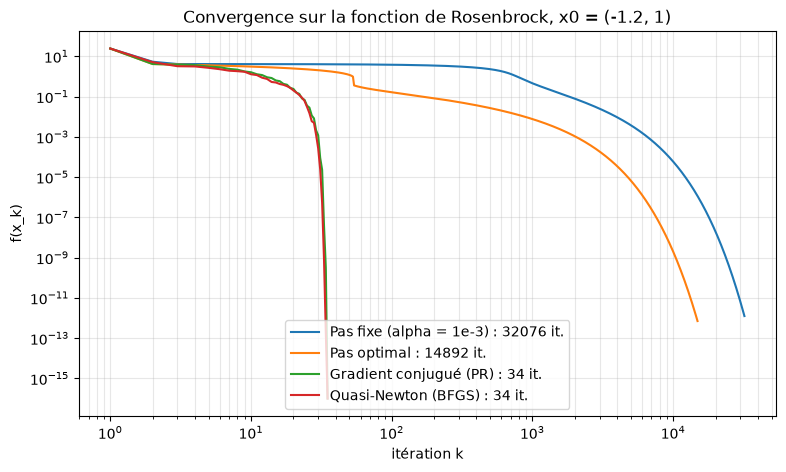

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
for hist, nom in [(hist_fixe, "Pas fixe (alpha = 1e-3)"),
                  (hist_opt, "Pas optimal"),
                  (hist_gc, "Gradient conjugué (PR)"),
                  (hist_qn, "Quasi-Newton (BFGS)")]:
    plt.loglog(range(1, len(hist) + 1), [max(v, 1e-16) for v in hist], label=f"{nom} : {len(hist) - 1} it.")
plt.xlabel("itération k")
plt.ylabel("f(x_k)")
plt.title("Convergence sur la fonction de Rosenbrock, x0 = (-1.2, 1)")
plt.grid(True, which="both", alpha=0.3)
plt.legend(loc="lower center")
plt.show()

## Conclusion

Nombre d'itérations obtenues (tolérance $\|\nabla f\| < 10^{-6}$) :

| Méthode | Information utilisée | Quadratique (n = 3) | Rosenbrock |
|---|---|---|---|
| Pas fixe | gradient | 30 ($\alpha = 0.3$), diverge si $\alpha > 2/\lambda_{max}$ | ~ 32 000 |
| Pas optimal | gradient + recherche linéaire exacte | 27 | ~ 15 000 |
| Gradient conjugué | gradient + direction précédente | **3 = n** | 34 |
| Quasi-Newton (BFGS) | gradient + approximation de la hessienne inverse | 9 | 34 |

- Le **pas fixe** est le plus simple, mais tout dépend du choix de $\alpha$ : trop petit la convergence est lente, trop grand la méthode diverge.
- Le **pas optimal** évite de choisir $\alpha$, mais deux directions successives sont orthogonales : on avance en zig-zag, ce qui reste très lent dans la vallée étroite de Rosenbrock.
- Le **gradient conjugué** supprime ce zig-zag pour un coût par itération presque identique ; sur la quadratique il converge en exactement $n$ itérations, comme prévu par la théorie.
- **Quasi-Newton** atteint la même rapidité sur Rosenbrock avec une recherche linéaire inexacte (Wolfe), beaucoup moins coûteuse qu'une recherche exacte : il imite la méthode de Newton sans jamais calculer de hessienne.